<a href="https://colab.research.google.com/github/mugagga-dotcom/datascience-nlp/blob/main/Wine_Quality_ML_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Here we first upload the dataset



In [ ]:

from google.colab import files

uploaded = files.upload()


Saving winequality-white.csv to winequality-white (2).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/winequality-white.csv', sep=';')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


here we import our dataset and check for the first five rows

In [ ]:
df.shape

(4898, 12)

we check for the rows and columns of the dataset

In [ ]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

Here we check for the columns in our dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


we get the information on our dataset

In [ ]:
df["quality"].value_counts().sort_index()

,count
quality,
3,20
4,163
5,1457
6,2198
7,880
8,175
9,5


here we check for the quality of the dataset

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.854788,0.843868,3.80000,6.300000,6.80000,7.3000,14.20000
volatile acidity,4898.0,0.278241,0.100795,0.08000,0.210000,0.26000,0.3200,1.10000
citric acid,4898.0,0.334192,0.121020,0.00000,0.270000,0.32000,0.3900,1.66000
residual sugar,4898.0,6.391415,5.072058,0.60000,1.700000,5.20000,9.9000,65.80000
chlorides,4898.0,0.045772,0.021848,0.00900,0.036000,0.04300,0.0500,0.34600
free sulfur dioxide,4898.0,35.308085,17.007137,2.00000,23.000000,34.00000,46.0000,289.00000
total sulfur dioxide,4898.0,138.360657,42.498065,9.00000,108.000000,134.00000,167.0000,440.00000
density,4898.0,0.994027,0.002991,0.98711,0.991723,0.99374,0.9961,1.03898
pH,4898.0,3.188267,0.151001,2.72000,3.090000,3.18000,3.2800,3.82000
sulphates,4898.0,0.489847,0.114126,0.22000,0.410000,0.47000,0.5500,1.08000


This will show the mean, standard deviation, minimum, maximum, and quartiles for each variable

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 937


here we check for the number of duplicate rows

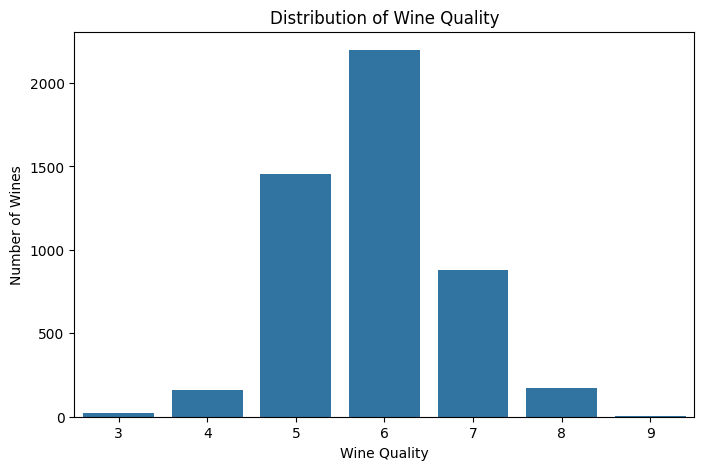

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='quality')

plt.title('Distribution of Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Number of Wines')

plt.show()

here we visualise the wine quality

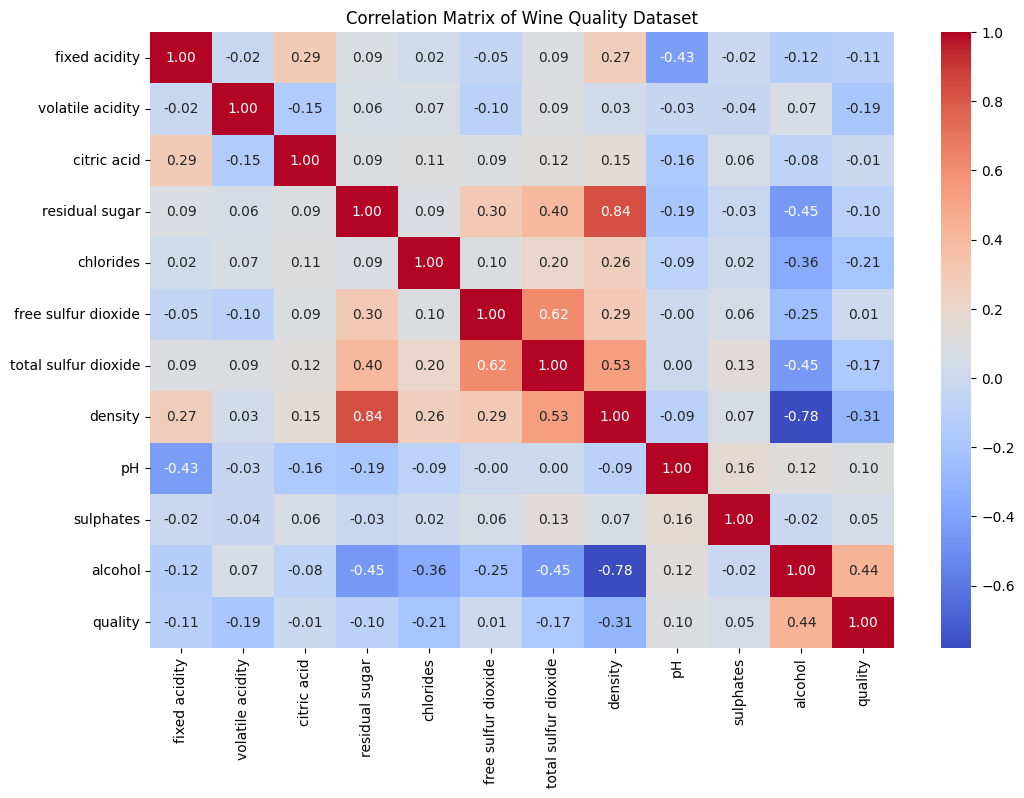

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Wine Quality Dataset')

plt.show()

this is the Correlation Matrix of Wine Quality Dataset

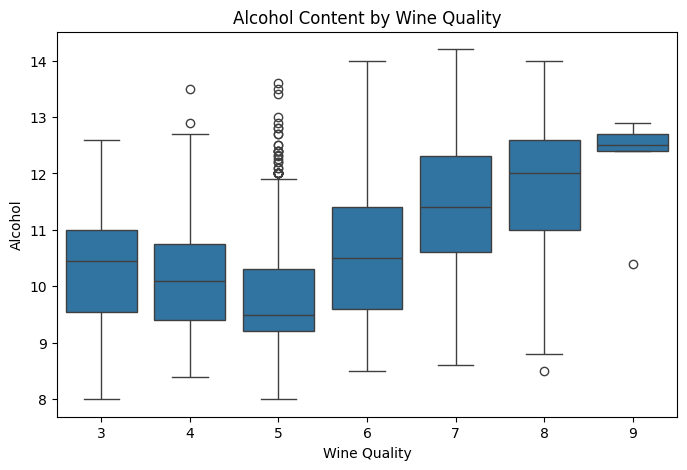

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='quality', y='alcohol')

plt.title('Alcohol Content by Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Alcohol')

plt.show()

this is a box plot to show the relationship between alcohol and quality

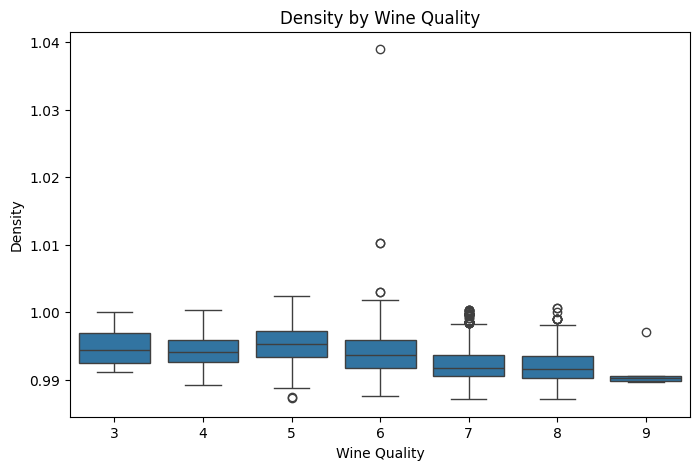

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='quality', y='density')

plt.title('Density by Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Density')

plt.show()

 A box plot to show the relationship between density and quality

In [ ]:
# Check number of duplicates
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check new size
print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows: 937
Dataset shape after removing duplicates: (3961, 12)


In [ ]:
# Create binary target variable
df['good_quality'] = (df['quality'] >= 7).astype(int)

# Display the distribution
print(df['good_quality'].value_counts())

good_quality
0    3136
1     825
Name: count, dtype: int64


In [ ]:
# Display percentages
print(df['good_quality'].value_counts(normalize=True) * 100)

good_quality
0    79.171926
1    20.828074
Name: proportion, dtype: float64


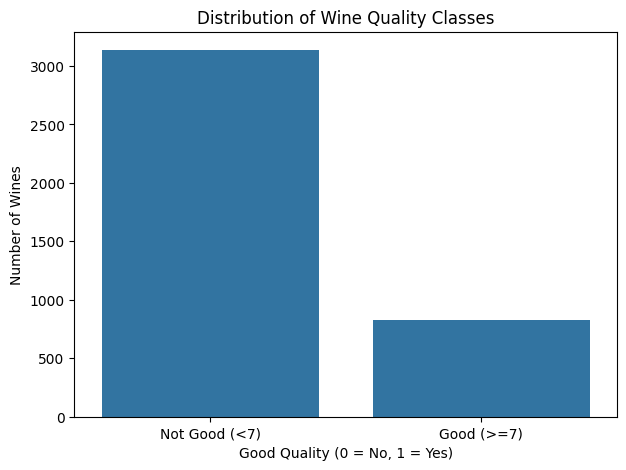

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='good_quality')

plt.title('Distribution of Wine Quality Classes')
plt.xlabel('Good Quality (0 = No, 1 = Yes)')
plt.ylabel('Number of Wines')

plt.xticks([0, 1], ['Not Good (<7)', 'Good (>=7)'])

plt.show()

Here we visualise our new target

In [ ]:
# Features
X = df.drop(columns=['quality', 'good_quality'])

# Target
y = df['good_quality']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3961, 11)
Target shape: (3961,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 3168
Testing samples: 793


We split our data into two the training and testing parts

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:

# STEP 3: Predict the wine classes using test data
y_pred = model.predict(X_test_scaled)

# Display the first 10 actual and predicted classes
print("Actual wine classes:", y_test[:10])
print("Predicted wine classes:", y_pred[:10])


Actual wine classes: 4032    0
1849    0
946     0
2309    0
183     0
4778    0
589     0
1007    0
2016    1
2296    1
Name: good_quality, dtype: int64
Predicted wine classes: [0 0 0 0 0 0 0 0 0 0]


model.fit() teaches the model patterns in the training data.



model.predict() uses those learned patterns to predict the wine classes.



y_test contains the correct answers for the test samples.



y_pred contains the model's predictions.

Here we are evaluating the model accuracy

In [ ]:

# STEP 4: Evaluate the model's performance
from sklearn.metrics import accuracy_score

# Calculate accuracy using all test samples
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy Percentage:", round(accuracy * 100, 2), "%")


Model Accuracy: 0.8247162673392182
Model Accuracy Percentage: 82.47 %


Confusion matrix — see which wine classes the model predicts correctly or confuses.



Classification report — calculate precision, recall and F1-score.



Visualizations — plot the model's performance.



Compare algorithms — test Logistic Regression against other classifiers.



Make a prediction for a new wine sample.

In [ ]:

# STEP 5: Generate the classification report
from sklearn.metrics import classification_report

# Compare actual labels with predicted labels
report = classification_report(
    y_test,
    y_pred,
    target_names=["Not Good Wine (<7)", "Good Wine (>=7)"],
    zero_division=0
)

print("Classification Report:")
print(report)


Classification Report:
                    precision    recall  f1-score   support

Not Good Wine (<7)       0.85      0.95      0.90       628
   Good Wine (>=7)       0.64      0.36      0.46       165

          accuracy                           0.82       793
         macro avg       0.74      0.65      0.68       793
      weighted avg       0.81      0.82      0.81       793



Precision: How often the model's predictions for a category are correct.



Recall: How many of the actual wines in a category the model identifies correctly.



F1-score: A balance between precision and recall.



Support: The number of actual test samples belonging to each category.

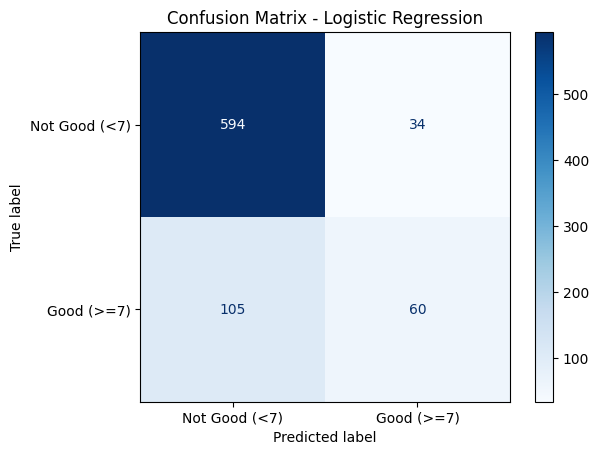

In [ ]:

# STEP 6: Visualize the confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the results
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Good (<7)", "Good (>=7)"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


The confusion matrix shows how many wines were classified correctly and how many were placed in the wrong category

In [ ]:

# Step 6: Import the Decision Tree model
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


DecisionTreeClassifier() creates the model.



max_depth=5 limits the tree's depth to help reduce overfitting.



random_state=42 makes the results reproducible.



.fit() trains the model using your training data.

In [ ]:

# Step 8: Evaluate model accuracy
from sklearn.metrics import accuracy_score, classification_report

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Model: Decision Tree")
print("Accuracy:", round(dt_accuracy, 4))
print("Accuracy percentage:", round(dt_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    zero_division=0
))


Model: Decision Tree
Accuracy: 0.797
Accuracy percentage: 79.7 %

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.88       628
           1       0.52      0.35      0.42       165

    accuracy                           0.80       793
   macro avg       0.68      0.63      0.65       793
weighted avg       0.78      0.80      0.78       793



Here we test our first model. We will start with Logistic Regression, a classification algorithm that can predict which of the three wine classes a sample belongs to. The Wine dataset has 178 samples and 13 chemical features.

In [ ]:

# STEP 2: Import the Logistic Regression algorithm
from sklearn.linear_model import LogisticRegression

# Create the machine learning model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model using the scaled training data
model.fit(X_train_scaled, y_train)

print("Model training completed successfully!")

Model training completed successfully!


Here we are going to compare logistic regression and decision tree

In [ ]:

# Step 9: Compare model accuracy

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy, dt_accuracy]
})

comparison["Accuracy (%)"] = (
    comparison["Accuracy"] * 100
).round(2)

display(comparison)


,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.824716,82.47
1,Decision Tree,0.796974,79.70
